In [206]:
import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import math
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

def lorenz96_rhs(x, F = 8.0):
    """
    Lorenz-96 vector field.

    x: Tensor of shape (..., N)
    F: scalar or tensor broadcastable to x[..., 0]

    Returns: dx/dt with same shape as x
    """
    # Periodic neighbors using roll
    x_ip1 = torch.roll(x, shifts=-1, dims=-1)  # x_{i+1}
    x_im1 = torch.roll(x, shifts=+1, dims=-1)  # x_{i-1}
    x_im2 = torch.roll(x, shifts=+2, dims=-1)  # x_{i-2}

    # dx_i/dt = (x_{i+1} - x_{i-2}) * x_{i-1} - x_i + F
    return (x_ip1 - x_im2) * x_im1 - x + torch.as_tensor(F, device=x.device, dtype=x.dtype)


def rk4_step(
    x,
    dt,
    rhs=lorenz96_rhs,
    rhs_args = (),
    rhs_kwargs = None,
):
    """
    One Runge-Kutta 4 step: x_{n+1} = x_n + dt/6*(k1 + 2k2 + 2k3 + k4).
    """
    if rhs_kwargs is None:
        rhs_kwargs = {}

    k1 = rhs(x, *rhs_args, **rhs_kwargs)
    k2 = rhs(x + 0.5 * dt * k1, *rhs_args, **rhs_kwargs)
    k3 = rhs(x + 0.5 * dt * k2, *rhs_args, **rhs_kwargs)
    k4 = rhs(x + dt * k3, *rhs_args, **rhs_kwargs)

    return x + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


@torch.no_grad()
def integrate_lorenz96(
    x0,
    dt,
    steps,
    F = 8.0,
    save_every= 1,
):
    """
    Integrate Lorenz-96 forward with RK4.

    x0: (..., N) initial condition
    dt: timestep
    steps: number of RK4 steps
    F: forcing
    save_every: store every k-th step (including step 0)

    Returns:
      traj: (T, ..., N) where T = steps//save_every + 1
    """
    x = x0.clone()
    out = [x0.clone()]
    

    rhs_kwargs = {"F": F}
    for s in range(1, steps + 1):
        x = rk4_step(x, dt, rhs=lorenz96_rhs, rhs_kwargs=rhs_kwargs)
        if (s % save_every) == 0:
            out.append(x.clone())

    return torch.stack(out, dim=0)


# Example usage:
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float32

    B, N = 100, 40
    T_full = 550
    T_train = 500
    high = 10
    low = 6
    traj = torch.zeros(T_full+1,B,N)
    F_list = torch.zeros(B)
    
    for i in range(B):
        x0 = torch.randn(N, device=device, dtype=dtype)
        F_list[i] = (high-low)*torch.rand(1)+low
        traj[:,i,:] = integrate_lorenz96(x0, dt=0.01, steps=T_full, F=F_list[i], save_every=1)

In [324]:
def pairwise_distances(X,Y):
    
    distance = torch.cdist(X,Y)
    
    return distance

def laplace_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = torch.exp(-D/sigma)
    
    return matrix

def gaussian_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = torch.exp(-D**2/(2*sigma**2))
    
    return matrix

def gaussian_prod_matrix(X,Y,sigma_u=1,sigma_F=1):
    
    D1 = pairwise_distances(X[:,:-1], Y[:,:-1])
    matrix1 = torch.exp(-D1**2/(2*sigma_u**2))

    D2 = pairwise_distances(X[:,-1][:,None], Y[:,-1][:,None])
    matrix2 = torch.exp(-D2**2/(2*sigma_F**2))
    
    matrix = matrix1+matrix2
    
    return matrix

def matern52_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = (1+math.sqrt(5)*D/sigma+5.0/3.0*D**2/sigma**2)*torch.exp(-math.sqrt(5)*D/sigma)
    
    return matrix

def poly_matrix(X,Y,c=0,d=1):
    
    inner = X @ Y.T
    
    matrix = (c+inner)**d
    
    return matrix

In [325]:
def kernel_regression(X_test,X_train,Y_train,lam=10**-5,kernel=gaussian_matrix, **kernel_params):
    
    K_test = kernel(X_test,X_train, **kernel_params)
    K_train = kernel(X_train,X_train, **kernel_params)
    I = torch.eye(K_train.shape[0], device=K_train.device, dtype=K_train.dtype)

    alpha = torch.linalg.solve(K_train + lam * I, Y_train)

    Y_test = K_test @ alpha

    return Y_test
    

In [326]:
L = 10

t0 = L - 1
t1 = T_train - 1
t_vals = list(range(t0, t1))
n_t = len(t_vals)

X = torch.zeros(B, n_t, N*L+1, device=traj.device, dtype=traj.dtype)
Y = torch.zeros(B, n_t, N)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = traj[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        X[j, i, :-1] = window.reshape(-1)
        Y[j, i, :] = traj[t+1, j, :]-traj[t, j, :]
    X[j,:,-1] = F_list[j]*torch.ones(n_t)  

In [ ]:
X_full = X.reshape(n_t*B,N*L+1)
Y_full = Y.reshape(n_t*B,N)

sample_size = 6000
idx = torch.randperm(X_full.shape[0], device=X_full.device)[:sample_size]

X_sample = X_full[idx]
Y_sample = Y_full[idx]

X_last = torch.zeros(B,N*L+1)
Y_last = torch.zeros(B,N)


for j in range(B):
    window = traj[T_train-L+1:T_train+1, j, :]        # (L,p)
    window = torch.flip(window, dims=[0])    # newest->oldest
    X_last[j, :-1] = window.reshape(-1)
    Y_last[j, :] = traj[T_train+1, j, :]-traj[T_train, j, :]
    X_last[j,-1] = F_list[j]

Xu = X_sample[:, :-1]
Du = torch.cdist(Xu, Xu)
sigma_u = torch.median(Du[Du > 0])

Xf = X_sample[:, -1]
Df = torch.cdist(Xf[:,None], Xf[:,None])
sigma_F = torch.median(Df[Df > 0])

Delta_t_next = kernel_regression(X_last,X_sample,Y_sample,lam=10**-5,kernel=gaussian_prod_matrix,sigma_u=sigma_u,sigma_F=sigma_F)

traj_next = traj[T_train,:,:] + Delta_t_next

In [377]:
state_error_train = torch.linalg.norm(traj_next-traj[T_train+1, :, :])/torch.linalg.norm(traj[T_train+1, :, :])
print(state_error_train)

tensor(0.0061)


In [ ]:
pers_error_train = torch.linalg.norm(traj[T_train, :, :]-traj[T_train+1, :, :])/torch.linalg.norm(traj[T_train+1, :, :])
print(pers_error_train)

tensor(0.0437)


In [379]:
step_error_train = torch.linalg.norm(Delta_t_next-Y_last)/torch.linalg.norm(Y_last)
print(step_error_train)

tensor(0.1385)


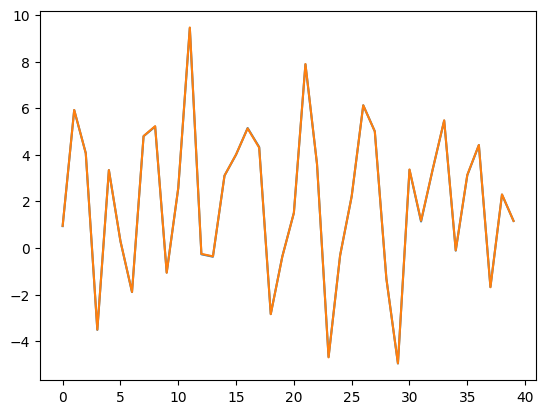

In [445]:
plt.plot(traj_next[5,:])
plt.plot(traj[T_train+1, 5, :])
#plt.plot(traj[T_train, 5, :])
#plt.plot(traj[540, 30, :])

In [381]:
traj_test_insample = torch.zeros(T_full+1,B,N)
F_test_insample = torch.zeros(B)

for i in range(B):
    x0 = torch.randn(N, device=device, dtype=dtype)
    F_test_insample[i] = (high-low)*torch.rand(1)+low
    traj_test_insample[:,i,:] = integrate_lorenz96(x0, dt=0.01, steps=T_full, F=F_test_insample[i], save_every=1)

In [407]:
X_test_insample = torch.zeros(B, n_t, N*L+1, device=traj.device, dtype=traj.dtype)

X_pred_insample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Y_test_insample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Delta_t_insample = torch.zeros(B,n_t, N, device=traj.device, dtype=traj.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = traj_test_insample[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        X_test_insample[j, i, :-1] = window.reshape(-1)
        Y_test_insample[j, i, :] = traj_test_insample[t+1, j, :]-traj_test_insample[t, j, :]
        X_test_insample[j,i,-1] = F_test_insample[j]
    Delta_t_insample[j,:,:] = kernel_regression(X_test_insample[j,:,:],X_sample,Y_sample,lam=10**-5,kernel=gaussian_prod_matrix,sigma_u=sigma_u,sigma_F=sigma_F)
    X_pred_insample[j,:,:] = traj_test_insample[t_vals,j,:]+Delta_t_insample[j,:,:]


In [478]:

horizon = 20

# traj_test_insample: [T, B, N]
# Assume T_train is the last in-sample index used as current time
# Need L past states ending at T_train
window = traj_test_insample[T_train - L + 1 : T_train + 1].flip(0).clone()   # [L, B, N], newest -> oldest

# Outputs
X_forecast_insample = torch.zeros(B, horizon, N, device=traj_test_insample.device, dtype=traj_test_insample.dtype)
X_test_insample     = torch.zeros(B, horizon, L * N + 1, device=traj_test_insample.device, dtype=traj_test_insample.dtype)
Y_test_insample     = torch.zeros(B, horizon, N, device=traj_test_insample.device, dtype=traj_test_insample.dtype)
Delta_t_insample    = torch.zeros(B, horizon, N, device=traj_test_insample.device, dtype=traj_test_insample.dtype)

for i in range(horizon):
    # window: [L, B, N] -> [B, L, N] -> [B, L*N]
    x_hist = window.permute(1, 0, 2).reshape(B, L * N)

    # append parameter/forcing feature
    # F_test_insample assumed shape [B]
    x_query = torch.cat([x_hist, F_test_insample[:, None]], dim=1)   # [B, L*N+1]
    X_test_insample[:, i, :] = x_query

    # true target increment, only for evaluation
    Y_test_insample[:, i, :] = (
        traj_test_insample[T_train + i + 1] - traj_test_insample[T_train + i]
    )

    # batched regression: should return [B, N]
    delta = kernel_regression(
        x_query,
        X_sample,
        Y_sample,
        lam=1e-5,
        kernel=gaussian_prod_matrix,
        sigma_u=sigma_u,
        sigma_F=sigma_F,
    )

    Delta_t_insample[:, i, :] = delta

    # current state is the newest one in the window
    current_state = window[0]                       # [B, N]
    next_state = current_state + delta             # [B, N]
    X_forecast_insample[:, i, :] = next_state

    # shift window down: newest stays at index 0
    window[1:] = window[:-1].clone()
    window[0] = next_state


torch.Size([100])

In [408]:
step_error_insample = torch.linalg.norm(Delta_t_insample-Y_test_insample)/torch.linalg.norm(Y_test_insample)
print(step_error_insample)

tensor(0.2227)


In [425]:
model_error_insample = torch.linalg.norm(torch.permute(X_pred_insample,(1,0,2))-traj_test_insample[t0+1:t1+1,:,:])/torch.linalg.norm(traj_test_insample[t_vals,:,:])
print(model_error_insample)

tensor(0.0102)


In [427]:
pers_error_insample = torch.linalg.norm(traj_test_insample[t_vals,:,:]-traj_test_insample[t0+1:t1+1,:,:])/torch.linalg.norm(traj_test_insample[t_vals,:,:])
print(pers_error_insample)

tensor(0.0456)


In [420]:
traj_test_insample[t0+1:t1+1,:,:].shape

torch.Size([490, 100, 40])

In [421]:
traj_test_insample[t_vals,:,:].shape

torch.Size([490, 100, 40])

In [428]:
high_test = 12
low_test = 16

traj_test_outsample = torch.zeros(T_full+1,B,N)
F_test_outsample = torch.zeros(B)

for i in range(B):
    x0 = torch.randn(N, device=device, dtype=dtype)
    F_test_outsample[i] = (high_test-low_test)*torch.rand(1)+low_test
    traj_test_outsample[:,i,:] = integrate_lorenz96(x0, dt=0.01, steps=T_full, F=F_test_outsample[i], save_every=1)

In [ ]:
X_test_outsample = torch.zeros(B, n_t, N*L+1, device=traj.device, dtype=traj.dtype)

X_pred_outsample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Y_test_outsample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Delta_t_outsample = torch.zeros(B,n_t, N, device=traj.device, dtype=traj.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = traj_test_outsample[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        X_test_outsample[j, i, :-1] = window.reshape(-1)
        Y_test_outsample[j, i, :] = traj_test_outsample[t+1, j, :]-traj_test_outsample[t, j, :]
        X_test_outsample[j,i,-1] = F_test_outsample[j]
    Delta_t_outsample[j,:,:] = kernel_regression(X_test_outsample[j,:,:],X_sample,Y_sample,lam=10**-5,kernel=gaussian_prod_matrix,sigma_u=sigma_u,sigma_F=sigma_F)
    X_pred_outsample[j,:,:] = traj_test_outsample[t_vals,j,:]+Delta_t_outsample[j,:,:]

In [442]:
step_error_outsample = torch.linalg.norm(Delta_t_outsample-Y_test_outsample)/torch.linalg.norm(Y_test_outsample)
print(step_error_outsample)

tensor(0.4730)


In [443]:
model_error_outsample = torch.linalg.norm(torch.permute(X_pred_outsample,(1,0,2))-traj_test_outsample[t0+1:t1+1,:,:])/torch.linalg.norm(traj_test_outsample[t_vals,:,:])
print(model_error_outsample)

tensor(0.0330)


In [444]:
pers_error_outsample = torch.linalg.norm(traj_test_outsample[t_vals,:,:]-traj_test_outsample[t0+1:t1+1,:,:])/torch.linalg.norm(traj_test_outsample[t_vals,:,:])
print(pers_error_outsample)

tensor(0.0698)


In [479]:

horizon = 20

# traj_test_insample: [T, B, N]
# Assume T_train is the last in-sample index used as current time
# Need L past states ending at T_train
window = traj_test_outsample[T_train - L + 1 : T_train + 1].flip(0).clone()   # [L, B, N], newest -> oldest

# Outputs
X_forecast_outsample = torch.zeros(B, horizon, N, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)
X_test_outsample     = torch.zeros(B, horizon, L * N + 1, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)
Y_test_outsample     = torch.zeros(B, horizon, N, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)
Delta_t_outsample    = torch.zeros(B, horizon, N, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)

for i in range(horizon):
    # window: [L, B, N] -> [B, L, N] -> [B, L*N]
    x_hist = window.permute(1, 0, 2).reshape(B, L * N)

    # append parameter/forcing feature
    # F_test_insample assumed shape [B]
    x_query = torch.cat([x_hist, F_test_outsample[:, None]], dim=1)   # [B, L*N+1]
    X_test_outsample[:, i, :] = x_query

    # true target increment, only for evaluation
    Y_test_outsample[:, i, :] = (
        traj_test_outsample[T_train + i + 1] - traj_test_outsample[T_train + i]
    )

    # batched regression: should return [B, N]
    delta = kernel_regression(
        x_query,
        X_sample,
        Y_sample,
        lam=1e-5,
        kernel=gaussian_prod_matrix,
        sigma_u=sigma_u,
        sigma_F=sigma_F,
    )

    Delta_t_outsample[:, i, :] = delta

    # current state is the newest one in the window
    current_state = window[0]                       # [B, N]
    next_state = current_state + delta             # [B, N]
    X_forecast_outsample[:, i, :] = next_state

    # shift window down: newest stays at index 0
    window[1:] = window[:-1].clone()
    window[0] = next_state